# Cassava Leaf Disease Classification

# Part A

In [ ]:
import json, os, time
import numpy as np, pandas as pd, torch, timm
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T

In [ ]:
DATA = str(next(__import__("pathlib").Path("/kaggle/input").rglob("label_num_to_disease_map.json")).parent)
OUT = "/kaggle/working"
MODEL = "convnext_small.fb_in22k_ft_in1k_384"
IMG, BS, EPOCHS, LR, FOLD, SEED = 384, 24, 10, 1e-4, 0, 42
torch.manual_seed(SEED); np.random.seed(SEED)
dev = "cuda"

In [ ]:
df = pd.read_csv(f"{DATA}/train.csv")
names = json.load(open(f"{DATA}/label_num_to_disease_map.json"))
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
tr_idx, va_idx = list(skf.split(df, df.label))[FOLD]

In [ ]:
mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = T.Compose([T.RandomResizedCrop(IMG, scale=(0.5, 1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.ColorJitter(0.2, 0.2, 0.2, 0.05), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])
val_tf = T.Compose([T.Resize(int(IMG * 1.07)), T.CenterCrop(IMG), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])

In [ ]:
class Leaves(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(f"{DATA}/train_images/{r.image_id}").convert("RGB")), r.label

In [ ]:
dl_tr = DataLoader(Leaves(df.iloc[tr_idx], train_tf), BS, shuffle=True, num_workers=4, pin_memory=True, drop_last=True)
dl_va = DataLoader(Leaves(df.iloc[va_idx], val_tf), BS * 2, num_workers=4, pin_memory=True)

In [ ]:
model = timm.create_model(MODEL, pretrained=True, num_classes=5, drop_path_rate=0.2).to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
steps = EPOCHS * len(dl_tr)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
crit = nn.CrossEntropyLoss(label_smoothing=0.1)   
scaler = torch.amp.GradScaler()

In [ ]:
@torch.no_grad()
def predict(tta=False):
    model.eval(); out = []
    for x, _ in dl_va:
        x = x.to(dev)
        with torch.autocast("cuda", dtype=torch.float16):
            p = model(x).softmax(1)
            if tta:
                p = (p + model(x.flip(3)).softmax(1) + model(x.flip(2)).softmax(1)) / 3
        out.append(p.float().cpu())
    return torch.cat(out).numpy()

In [ ]:
y_va = df.label.values[va_idx]
hist, best = [], 0.0
for ep in range(EPOCHS):
    model.train(); t0, tot = time.time(), 0.0
    for x, y in dl_tr:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = crit(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
    acc = accuracy_score(y_va, predict().argmax(1))
    hist.append({"epoch": ep + 1, "train_loss": tot / len(dl_tr), "val_acc": acc, "minutes": (time.time() - t0) / 60})
    print(hist[-1], flush=True)
    if acc > best:
        best = acc; torch.save(model.state_dict(), f"{OUT}/best.pt")

In [ ]:
model.load_state_dict(torch.load(f"{OUT}/best.pt"))
probs = predict(tta=True); pred = probs.argmax(1)
metrics = {
    "model": MODEL, "image_size": IMG, "epochs": EPOCHS, "validation": f"stratified holdout fold {FOLD} of 5 ({len(va_idx)} images)",
    "val_accuracy_tta": round(accuracy_score(y_va, pred), 4),
    "val_macro_f1_tta": round(f1_score(y_va, pred, average="macro"), 4),
    "best_epoch_accuracy_no_tta": round(best, 4),
    "per_class_f1": {names[str(k)]: round(v, 4) for k, v in enumerate(f1_score(y_va, pred, average=None))},
    "confusion_matrix": confusion_matrix(y_va, pred).tolist(), "class_names": [names[str(k)] for k in range(5)],
    "history": hist,
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
np.save(f"{OUT}/val_probs.npy", probs)
print(json.dumps({k: v for k, v in metrics.items() if k != "history"}, indent=2))

**Model A result:** accuracy 0.896, macro-F1 0.810.

Held-out accuracy per epoch: 0.876, 0.881, 0.887, 0.892, 0.891, 0.893, 0.888, 0.895, 0.895, 0.895.

# Part B

In [ ]:
import json, os, time
import numpy as np, pandas as pd, torch, timm
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T

DATA = str(next(__import__("pathlib").Path("/kaggle/input").rglob("label_num_to_disease_map.json")).parent)
OUT = "/kaggle/working"
MODEL = "tf_efficientnetv2_s.in21k_ft_in1k"
IMG, BS, EPOCHS, LR, FOLD, SEED = 448, 20, 10, 2e-4, 0, 42
torch.manual_seed(SEED); np.random.seed(SEED)
dev = "cuda"

df = pd.read_csv(f"{DATA}/train.csv")
names = json.load(open(f"{DATA}/label_num_to_disease_map.json"))
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
tr_idx, va_idx = list(skf.split(df, df.label))[FOLD]

mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = T.Compose([T.RandomResizedCrop(IMG, scale=(0.5, 1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.ColorJitter(0.2, 0.2, 0.2, 0.05), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])
val_tf = T.Compose([T.Resize(int(IMG * 1.07)), T.CenterCrop(IMG), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])


class Leaves(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(f"{DATA}/train_images/{r.image_id}").convert("RGB")), r.label


dl_tr = DataLoader(Leaves(df.iloc[tr_idx], train_tf), BS, shuffle=True, num_workers=4, pin_memory=True, drop_last=True)
dl_va = DataLoader(Leaves(df.iloc[va_idx], val_tf), BS * 2, num_workers=4, pin_memory=True)

model = timm.create_model(MODEL, pretrained=True, num_classes=5, drop_path_rate=0.2).to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
steps = EPOCHS * len(dl_tr)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
crit = nn.CrossEntropyLoss(label_smoothing=0.1) 
scaler = torch.amp.GradScaler()
cutmix = T.CutMix(num_classes=5, alpha=1.0) 


@torch.no_grad()
def predict(tta=False):
    model.eval(); out = []
    for x, _ in dl_va:
        x = x.to(dev)
        with torch.autocast("cuda", dtype=torch.float16):
            p = model(x).softmax(1)
            if tta:
                p = (p + model(x.flip(3)).softmax(1) + model(x.flip(2)).softmax(1)) / 3
        out.append(p.float().cpu())
    return torch.cat(out).numpy()

In [ ]:
y_va = df.label.values[va_idx]
hist, best = [], 0.0
for ep in range(EPOCHS):
    model.train(); t0, tot = time.time(), 0.0
    for x, y in dl_tr:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        if np.random.rand() < 0.5:
            x, y = cutmix(x, y)  
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = crit(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
    acc = accuracy_score(y_va, predict().argmax(1))
    hist.append({"epoch": ep + 1, "train_loss": tot / len(dl_tr), "val_acc": acc, "minutes": (time.time() - t0) / 60})
    print(hist[-1], flush=True)
    if acc > best:
        best = acc; torch.save(model.state_dict(), f"{OUT}/best.pt")

In [ ]:
model.load_state_dict(torch.load(f"{OUT}/best.pt"))
probs = predict(tta=True); pred = probs.argmax(1)
metrics = {
    "model": MODEL, "image_size": IMG, "epochs": EPOCHS, "validation": f"stratified holdout fold {FOLD} of 5 ({len(va_idx)} images)",
    "val_accuracy_tta": round(accuracy_score(y_va, pred), 4),
    "val_macro_f1_tta": round(f1_score(y_va, pred, average="macro"), 4),
    "best_epoch_accuracy_no_tta": round(best, 4),
    "per_class_f1": {names[str(k)]: round(v, 4) for k, v in enumerate(f1_score(y_va, pred, average=None))},
    "confusion_matrix": confusion_matrix(y_va, pred).tolist(), "class_names": [names[str(k)] for k in range(5)],
    "history": hist,
}

In [ ]:
p1 = np.load(f"{OUT}/val_probs.npy")  
ens = (p1 + probs) / 2
metrics["ensemble"] = {
    "members": ["convnext_small.fb_in22k_ft_in1k_384 @384", f"{MODEL} @{IMG}"],
    "model1_accuracy": round(accuracy_score(y_va, p1.argmax(1)), 4),
    "accuracy": round(accuracy_score(y_va, ens.argmax(1)), 4),
    "macro_f1": round(f1_score(y_va, ens.argmax(1), average="macro"), 4),
    "per_class_f1": {names[str(k)]: round(v, 4) for k, v in enumerate(f1_score(y_va, ens.argmax(1), average=None))},
    "confusion_matrix": confusion_matrix(y_va, ens.argmax(1)).tolist(),
}
np.save(f"{OUT}/val_probs_ensemble.npy", ens)
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
np.save(f"{OUT}/val_probs.npy", probs)
print(json.dumps({k: v for k, v in metrics.items() if k != "history"}, indent=2))

## Results on the 4,280 held-out photos

| model | accuracy | macro-F1 |
|---|---|---|
| ConvNeXt-Small @384 | 0.896 | 0.810 |
| EfficientNetV2-S @448 | 0.896 | 0.808 |
| **average of both** | **0.899** | **0.816** |

Per-class F1:

| model | Cassava Bacterial Blight | Cassava Brown Streak Disease | Cassava Green Mottle | Cassava Mosaic Disease | Healthy |
|---|---|---|---|---|---|
| ConvNeXt | 0.684 | 0.817 | 0.820 | 0.964 | 0.764 |
| EfficientNetV2 | 0.668 | 0.815 | 0.830 | 0.964 | 0.763 |
| average | 0.689 | 0.823 | 0.828 | 0.965 | 0.775 |


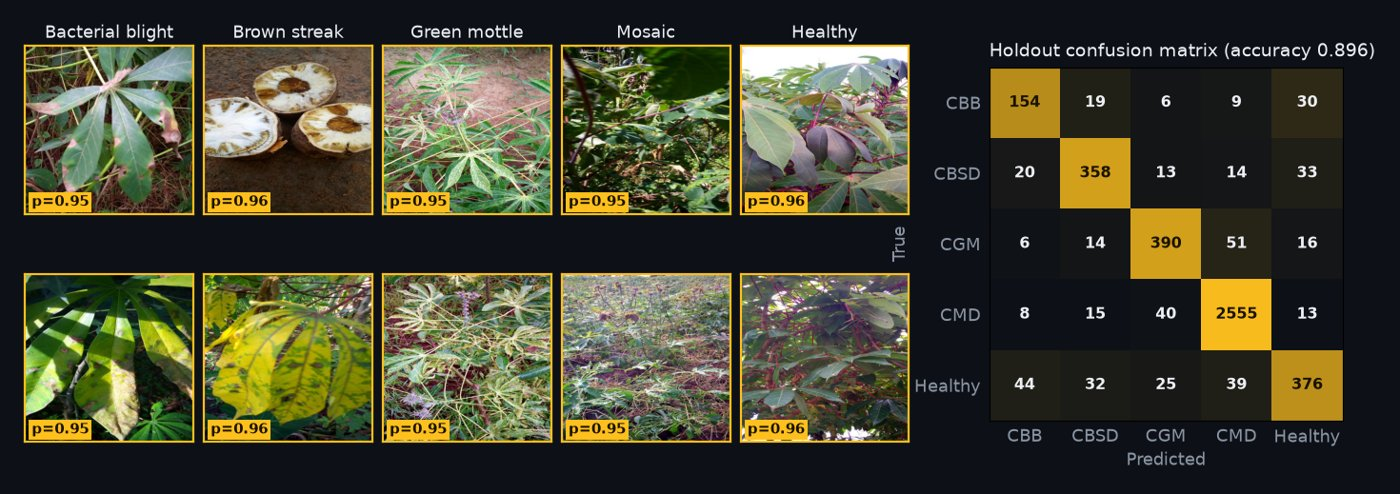

*Model 1 (ConvNeXt): confident held-out examples per class and its confusion matrix*